# NLP-Themenanalyse von Beschwerdetexten

Dieses Notebook untersucht, worüber sich Bahnkundinnen und -kunden am häufigsten beschweren. Datengrundlage ist GermEval 2017, ein frei verfügbarer Datensatz mit deutschsprachigen Beiträgen über die Deutsche Bahn.

Das Notebook läuft von oben nach unten durch. Zuerst werden die Daten geladen und auf Beschwerden gefiltert, dann vorverarbeitet und in Vektoren umgewandelt. Anschließend werden die Themen extrahiert und zum Schluss dargestellt.

Portfolio zum IU-Kurs „Projekt: Data Analysis" (DLBDSEDA02) entstanden.

## 0. Setup

Die folgende Zelle installiert die Pakete und das deutsche spaCy-Modell. Notwendig ist das nur in Google Colab. Lokal sind die Pakete bereits vorhanden, die Zelle läuft dann ohne Wirkung durch.

In [1]:
!pip install pandas scikit-learn spacy matplotlib wordcloud gensim -q
!python -m spacy download de_core_news_sm -q


[notice] A new release of pip is available: 24.0 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')



[notice] A new release of pip is available: 24.0 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%matplotlib inline
import os
import re
import numpy as np
import pandas as pd
import spacy
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import NMF, LatentDirichletAllocation
import matplotlib.pyplot as plt
from wordcloud import WordCloud

nlp = spacy.load("de_core_news_sm", disable=["parser", "ner"])

## 1. Daten laden

Als Datenquelle dient GermEval 2017 mit rund 19.400 öffentlichen deutschsprachigen Beiträgen über die Deutsche Bahn. Der Großteil der Daten stammt aus sozialen Netzwerken, überwiegend von Twitter und Facebook. Der Rest verteilt sich auf Foren, Nachrichtenseiten und einzelne Webseiten. Die Bahn ist ein öffentlicher Dienstleister, damit liegt der Datensatz nah am Anwendungsfall der Aufgabenstellung. Liegt eine lokale Kopie unter `data/germeval.csv` vor, wird sie von dort gelesen, sonst holt das Notebook die Daten von Hugging Face.

Für die Analyse bleiben nur die Texte übrig, die im Datensatz als relevant und zugleich negativ markiert sind. Das sind knapp 4.900 Beiträge, und dabei handelt es sich tatsächlich um Beschwerden und nicht um Lob oder Smalltalk.

In [3]:
DATA_URL = "https://huggingface.co/datasets/akash418/germeval_2017/resolve/main/train.csv"
LOCAL_CSV = "data/germeval.csv"

# Beim ersten Lauf von Hugging Face laden und lokal ablegen, danach geht es offline
if os.path.exists(LOCAL_CSV):
    df = pd.read_csv(LOCAL_CSV)
    print(f"Lokal geladen: {len(df)} Dokumente")
else:
    df = pd.read_csv(DATA_URL)
    print(f"Von Hugging Face geladen: {len(df)} Dokumente")

n_roh = len(df)
df["text"] = df["text"].astype(str).str.strip()
df = df.drop_duplicates(subset="text")
duplicates = n_roh - len(df)
print(f"Nach Duplikat-Filter: {len(df)} Dokumente ({duplicates} Duplikate entfernt)")

# Nur echte Beschwerden behalten: relevant und negatives Sentiment.
df = df[df["relevance"] & (df["sentiment"] == "negative")].reset_index(drop=True)
print(f"Nach Beschwerden-Filter (relevant & negativ): {len(df)} Dokumente")
df[["text"]].sample(5, random_state=24)

Lokal geladen: 19432 Dokumente
Nach Duplikat-Filter: 18551 Dokumente (881 Duplikate entfernt)
Nach Beschwerden-Filter (relevant & negativ): 4863 Dokumente


,text
3567,"Tja, auch die #Bahn kämpft auf der Strecke von..."
1989,Wie die Bahn beim Gütertransport versagt https...
1865,Noch schlimmer als Cover-Songs mit Gitarre am ...
4122,Warum bleibt die S-Bahn kurz vor'm Bahnhof ste...
389,@orot_l Ein Ticketkauf ist über die App und ba...


## 2. Vorverarbeitung

Zuerst werden die Texte kleingeschrieben, anschließend URLs und @-Namen entfernt. Den Rest übernimmt spaCy. Die Texte werden in Tokens zerlegt und jedes Token auf seine Grundform zurückgeführt, damit „fährt“, „fuhr“ und „gefahren“ später als ein Wort gezählt werden. Am Ende bleiben nur Wörter, die aus Buchstaben bestehen, keine Stoppwörter sind und mindestens drei Zeichen haben.

Über `nlp.pipe` läuft die Verarbeitung im Batch. Bei knapp 5.000 Texten ist das spürbar schneller, als `nlp()` in einer Schleife aufzurufen.

In [4]:
# Kleinschreibung und Entfernen von URLs und @-Namen
def clean_regex(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    return text

# Behält nur relevante Grundformen (keine Füll- und Kurzwörter)
def lemmas_from_doc(doc):
    words = []
    for t in doc:
        lemma = t.lemma_.lower()
        if t.is_alpha and not t.is_stop and len(lemma) >= 3:
            words.append(lemma)
    return " ".join(words)


cleaned = []
for t in df["text"]:
    cleaned.append(clean_regex(t))

docs = []
for doc in nlp.pipe(cleaned, batch_size=500):
    docs.append(lemmas_from_doc(doc))

print("Beispiel (vorher): ", df["text"].iloc[0])
print("Beispiel (nachher):", docs[0])

Beispiel (vorher):  RT @FritzQuincke: @DB_Bahn @_AKHH_ Was lernt die Bahn wieder nicht: Ohne Redundanz geht es nicht, weil kein System oder Mensch perfekt ist.
Beispiel (nachher): lernen bahn redundanz system mensch perfekt


## 3. Vektorisierung

Die Modelle brauchen Zahlen statt Text. Dafür kommen zwei Verfahren infrage, die hier beide berechnet werden. Bag-of-Words zählt lediglich, wie oft ein Wort in einem Dokument vorkommt. TF-IDF zählt ebenfalls, senkt den Wert aber, je häufiger das Wort im gesamten Korpus vorkommt. Ein Wort, das in fast jeder Beschwerde auftaucht, bekommt dort also wenig Gewicht.

Vorher wird noch eine eigene Stoppwortliste abgezogen. Darin stehen zum einen Wörter, die in diesem Korpus überall vorkommen und deshalb nichts unterscheiden, etwa „bahn“ oder „db“. Zum anderen stehen dort Städtenamen. Sie sagen etwas über den Ort aus, aber nichts über das Anliegen.

Die Zelle gibt zwei Übersichten aus. Die erste stellt die häufigsten BoW-Wörter den am stärksten gewichteten TF-IDF-Wörtern gegenüber und zeigt, wie weit die beiden Verfahren auseinanderliegen. Die zweite zählt, in wie vielen Beschwerden die häufigsten Wörter überhaupt vorkommen. Daran lässt sich ablesen, ob die Schwelle max_df=0.5 in diesem Korpus etwas bewirkt.

In [5]:
# Domänenspezifische Rauschwörter
EXTRA_STOPWORDS = ["deutsch", "deutsche", "deutschen", "bahn", "db", "mal", "gutefrage", "net", "nen", "hab",
                   "hallo", "einfach", "eigentlich", "umsonst", "letzter", "nächster", "normal", "sogar",
                   "montag", "dienstag", "mittwoch", "donnerstag", "freitag", "samstag", "sonntag", "fast", "via"]

# Städte-/Regionsnamen (für die Themen-Analyse nicht relevant)
CITY_STOPWORDS = ["berlin", "berliner", "münchen", "hamburg", "köln", "kölner", "stuttgart",
                  "hannover", "leipzig", "bayern", "frankfurt", "bremen", "dresden"]


STOPWORDS = EXTRA_STOPWORDS + CITY_STOPWORDS

# Erstellung der Bag of Words Matrix
bow_vectorizer = CountVectorizer(min_df=10, max_df=0.5, stop_words=STOPWORDS)
bow_matrix = bow_vectorizer.fit_transform(docs)

# Erstellung der TF-IDF Matrix (Gewichtet nach Häufigkeit und Seltenheit)
tfidf_vectorizer = TfidfVectorizer(min_df=10, max_df=0.5, stop_words=STOPWORDS)
tfidf_matrix = tfidf_vectorizer.fit_transform(docs)

print("Bag-of-Words:", bow_matrix.shape)
print("TF-IDF:      ", tfidf_matrix.shape)

# Stellt die häufigsten BoW-Wörter den stärksten TF-IDF-Gewichten gegenüber
bow_words = bow_vectorizer.get_feature_names_out()
tfidf_words = tfidf_vectorizer.get_feature_names_out()
bow_sums = np.asarray(bow_matrix.sum(axis=0)).ravel()
tfidf_means = np.asarray(tfidf_matrix.mean(axis=0)).ravel()
bow_top = bow_sums.argsort()[::-1][:15]
tfidf_top = tfidf_means.argsort()[::-1][:15]

print(f"\n{'BoW (häufigste)':22s} TF-IDF (stärkste Gewichte)")
print("-" * 50)
for rank in range(15):
    print(f"{bow_words[bow_top[rank]]:22s} {tfidf_words[tfidf_top[rank]]}")

# Dokumentfrequenz der häufigsten Wörter, zeigt warum max_df=0.5 hier nicht greift
doc_freq = np.asarray((bow_matrix > 0).sum(axis=0)).ravel() / bow_matrix.shape[0]
print("\nHöchste Dokumentfrequenz:")
for i in doc_freq.argsort()[::-1][:5]:
    print(f"  {bow_words[i]:14s} {100 * doc_freq[i]:5.2f} %")

Bag-of-Words: (4863, 910)
TF-IDF:       (4863, 910)

BoW (häufigste)        TF-IDF (stärkste Gewichte)
--------------------------------------------------
fahren                 fahren
zug                    verspätung
verspätung             zug
stehen                 stehen
ice                    minute
minute                 ice
strecke                strecke
züge                   züge
störung                störung
bahnhof                bus
bus                    hbf
hbf                    problem
problem                bahnhof
streik                 voll
stunde                 streik

Höchste Dokumentfrequenz:
  fahren         11.31 %
  zug             9.25 %
  verspätung      8.62 %
  stehen          6.07 %
  minute          4.96 %


## 4. Wahl der Themenzahl (k)

Für die Themenzahl gibt es keinen festen Wert. Sie wird hier von zwei Seiten bestimmt. Zuerst rechnerisch, über die Ellbogen-Methode am Rekonstruktionsfehler der NMF und über den Coherence Score (c_v). Danach folgt die inhaltliche Prüfung. Die gefundenen Themen werden für verschiedene k gegenübergestellt und daraufhin beurteilt, ob sie sich sinnvoll voneinander abgrenzen. Beide Kennzahlen werden auf dem vollständigen gefilterten Datensatz berechnet.

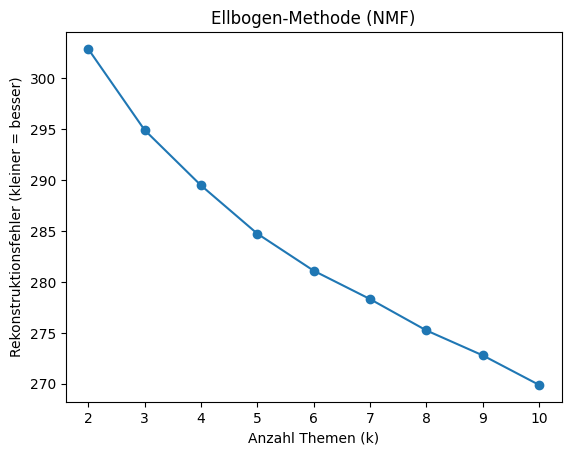

In [6]:
# Ellbogen-Methode: NMF-Rekonstruktionsfehler je Themenzahl
k_values = []
errors = []
for k in range(2, 11):
    model = NMF(n_components=k, init="nndsvda", beta_loss="kullback-leibler",
                solver="mu", max_iter=200, random_state=24)
    model.fit(tfidf_matrix)
    k_values.append(k)
    errors.append(model.reconstruction_err_)

plt.plot(k_values, errors, marker="o")
plt.xlabel("Anzahl Themen (k)")
plt.ylabel("Rekonstruktionsfehler (kleiner = besser)")
plt.title("Ellbogen-Methode (NMF)")
plt.show()

k=2: Coherence=0.4437
k=3: Coherence=0.4624
k=4: Coherence=0.4733
k=5: Coherence=0.4439
k=6: Coherence=0.3924
k=7: Coherence=0.4377
k=8: Coherence=0.4562
k=9: Coherence=0.4234
k=10: Coherence=0.4124


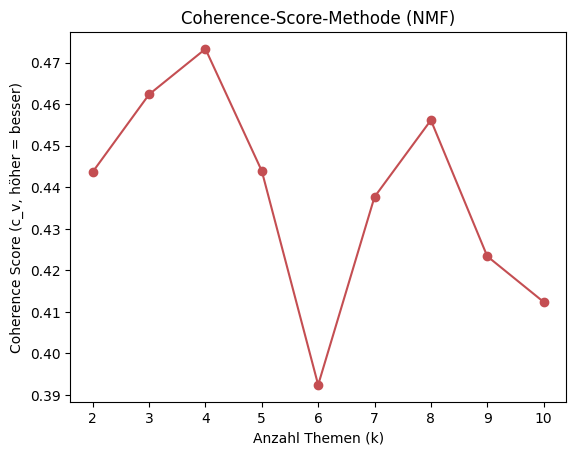

In [7]:
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel

# Berechnet und zeichnet den Kohärenzwert (C_v) bei unterschiedlicher Themenanzahl
words = tfidf_vectorizer.get_feature_names_out()

texts_tokens = []
for d in docs:
    texts_tokens.append(d.split())
dictionary = Dictionary(texts_tokens)

k_values = []
scores = []
for k in range(2, 11):
    model = NMF(n_components=k, init="nndsvda", beta_loss="kullback-leibler",
                solver="mu", max_iter=200, random_state=24)
    model.fit(tfidf_matrix)
    topics = []
    for topic in model.components_:
        top_words = []
        for i in topic.argsort()[::-1][:10]:
            top_words.append(words[i])
        topics.append(top_words)
    cm = CoherenceModel(topics=topics, texts=texts_tokens,
                        dictionary=dictionary, coherence="c_v", processes=1)
    k_values.append(k)
    scores.append(cm.get_coherence())
    print(f"k={k}: Coherence={scores[-1]:.4f}")

plt.plot(k_values, scores, marker="o", color="#C44E52")
plt.xlabel("Anzahl Themen (k)")
plt.ylabel("Coherence Score (c_v, höher = besser)")
plt.title("Coherence-Score-Methode (NMF)")
plt.show()

Beide Kennzahlen helfen hier nur begrenzt weiter. Der Rekonstruktionsfehler sinkt zwar durchgehend, aber der Rückgang wird von Schritt zu Schritt kleiner. Zwischen k=2 und k=3 sind es rund 8 Punkte, ab k=7 weniger als 3. Die Kurve flacht damit allmählich ab, ohne irgendwo den deutlichen Knick zu bilden, an dem sich eine Themenzahl ablesen ließe. Beim Coherence Score sieht es ähnlich aus. Er schwankt über den ganzen Bereich zwischen etwa 0,39 und 0,47 und hat kein klares Maximum. Der höchste Wert liegt bei k=4 mit 0,473. Mit 0,462 bei k=3 und 0,456 bei k=8 liegen zwei weitere Werte aber so dicht daneben, dass sich daraus keine Themenzahl ableiten lässt.

Da weder die Ellbogen-Methode noch der Coherence Score eine Themenzahl liefern, werden die Themen für k=3 bis k=6 direkt verglichen. Die nächste Zelle gibt je Themenzahl die acht wichtigsten Wörter pro Thema aus, dazu den Anteil der Beschwerden, der auf das Thema entfällt. Maßgeblich ist, ob die Themen voneinander getrennt bleiben oder ob mehrere Anliegen in einem Thema zusammenfallen.

In [8]:
for k in (3, 4, 5, 6):
    model = NMF(n_components=k, init="nndsvda", beta_loss="kullback-leibler",
                solver="mu", max_iter=200, random_state=24)
    model.fit(tfidf_matrix)

    doc_topic = model.transform(tfidf_matrix)
    counts = np.bincount(doc_topic.argmax(axis=1), minlength=k)
    words = tfidf_vectorizer.get_feature_names_out()

    print(f"--- k={k} ---")
    for i, topic in enumerate(model.components_):
        top_words = [words[j] for j in topic.argsort()[::-1][:8]]
        anteil = 100 * counts[i] / len(doc_topic)
        print(f"  Thema {i + 1} [{anteil:4.1f}% der Beschwerden]: {', '.join(top_words)}")
    print()

--- k=3 ---
  Thema 1 [38.4% der Beschwerden]: verspätung, zug, minute, fahren, problem, stunde, spät, warten
  Thema 2 [33.3% der Beschwerden]: fahren, voll, bus, streik, mensch, sehen, leute, gdl
  Thema 3 [28.4% der Beschwerden]: strecke, störung, hbf, ice, stehen, zug, sperren, sitzen

--- k=4 ---
  Thema 1 [28.5% der Beschwerden]: verspätung, minute, fahren, problem, spät, warten, richtung, stunde
  Thema 2 [26.3% der Beschwerden]: fahren, streik, bus, leute, gdl, finden, teuer, deutschland
  Thema 3 [19.5% der Beschwerden]: stehen, strecke, störung, hbf, sperren, züge, gleis, technisch
  Thema 4 [25.7% der Beschwerden]: zug, ice, voll, mensch, sitzen, funklöch, mann, notrufsystem

--- k=5 ---
  Thema 1 [24.5% der Beschwerden]: verspätung, minute, richtung, spät, warten, stunde, bekommen, bitte
  Thema 2 [22.7% der Beschwerden]: fahren, bus, leute, finden, teuer, deutschland, preis, schnell
  Thema 3 [18.0% der Beschwerden]: stehen, strecke, störung, hbf, sperren, züge, gleis, tec

Bei k=3 und k=4 verschwindet das Streik-Thema. Es geht in einem breiten Sammelthema zu Preisen und Bus auf. Bei k=5 stehen dagegen fünf gut unterscheidbare Themen da, nämlich Verspätung, Zustand der Züge, Preise und Bus, Störungen sowie Streik und Sicherheit. Bei k=6 kehrt sich der Effekt um, weil das Verspätungs-Thema in zwei unscharfe Hälften zerfällt. Passend dazu liegt die Coherence dort mit 0,392 am niedrigsten im gesamten getesteten Bereich. Die Wahl fällt deshalb auf k=5.

## 5. Themen-Extraktion

Es folgt die eigentliche Themenextraktion, mit zwei unterschiedlichen Verfahren. NMF ist ein lineares Verfahren und zerlegt die TF-IDF-Matrix in zwei kleinere Matrizen, deren Produkt das Original möglichst gut annähert. LDA geht anders vor und nimmt an, dass jedes Dokument aus einer Mischung von Themen entsteht und jedes Thema aus einer Wahrscheinlichkeitsverteilung über Wörter. Dafür benötigt LDA rohe Zählungen und läuft deshalb auf der Bag-of-Words-Matrix.

In [9]:
N_TOPICS = 5


# Findet Themen mit NMF (auf TF-IDF Matrix, Kullback-Leibler-Divergenz)
nmf_model = NMF(n_components=N_TOPICS, init="nndsvda", beta_loss="kullback-leibler",
                solver="mu", max_iter=200, random_state=24)
nmf_model.fit(tfidf_matrix)
print(f"NMF: {nmf_model.n_iter_} von max. 200 Durchläufen")


# Findet Themen mit LDA (auf Bag of Words Matrix)
lda_model = LatentDirichletAllocation(n_components=N_TOPICS, learning_method="batch",
                                      max_iter=200, evaluate_every=10, random_state=24)
lda_model.fit(bow_matrix)
print(f"LDA: {lda_model.n_iter_} von max. 200 Durchläufen\n")


# Gibt für jedes Thema die wichtigsten Wörter aus
def show_topics(model, vectorizer, n_words=10):
    words = vectorizer.get_feature_names_out()
    for topic_index, topic in enumerate(model.components_):
        top_indices = topic.argsort()[::-1][:n_words]
        top_words = []
        for i in top_indices:
            top_words.append(words[i])
        print(f"Thema {topic_index + 1}:", ", ".join(top_words))


print("=== NMF (auf TF-IDF) ===")
show_topics(nmf_model, tfidf_vectorizer)
print("\n=== LDA (auf Bag-of-Words) ===")
show_topics(lda_model, bow_vectorizer)


# Kohärenz beider Modelle auf derselben Tokenbasis
def coherence_of(model, vectorizer):
    words = vectorizer.get_feature_names_out()
    topics = []
    for topic in model.components_:
        topics.append([words[i] for i in topic.argsort()[::-1][:10]])
    return CoherenceModel(topics=topics, texts=texts_tokens, dictionary=dictionary,
                          coherence="c_v", processes=1).get_coherence()


print(f"\nCoherence (c_v)  NMF: {coherence_of(nmf_model, tfidf_vectorizer):.4f}"
      f"   LDA: {coherence_of(lda_model, bow_vectorizer):.4f}")

NMF: 70 von max. 200 Durchläufen
LDA: 89 von max. 200 Durchläufen

=== NMF (auf TF-IDF) ===
Thema 1: verspätung, minute, richtung, spät, warten, stunde, bekommen, bitte, dank, laufen
Thema 2: fahren, bus, leute, finden, teuer, deutschland, preis, schnell, sehen, nehmen
Thema 3: stehen, strecke, störung, hbf, sperren, züge, gleis, technisch, verspätungen, linie
Thema 4: zug, ice, voll, mensch, sitzen, mann, frau, klimaanlage, problem, wagen
Thema 5: streik, gdl, funklöch, notrufsystem, denken, sicherheitsrisiken, evg, bahnstreik, ramelow, nachricht

=== LDA (auf Bag-of-Words) ===
Thema 1: fahren, sperren, mann, voll, mensch, zug, bahnhof, frau, bus, sitzen
Thema 2: streik, gdl, richtung, evg, züge, fallen, schlichtung, funktionieren, problem, haltestelle
Thema 3: verspätung, minute, zug, fahren, stehen, warten, stunde, spät, ramelow, dank
Thema 4: fahren, ticket, teuer, finden, stehen, kunde, pünktlich, preis, bekommen, personenverkehr
Thema 5: ice, störung, hbf, strecke, gleis, zug, ha

## 6. Visualisierung

Pro Verfahren gibt es zwei Darstellungen. Die Wortwolken zeigen je Thema die 15 wichtigsten Wörter, wobei die Schriftgröße dem Gewicht im Thema entspricht. Das Balkendiagramm ordnet jede Beschwerde ihrem stärksten Thema zu und zählt durch. So lassen sich die Themen nicht nur inhaltlich vergleichen, sondern auch nach ihrer Häufigkeit sortieren.

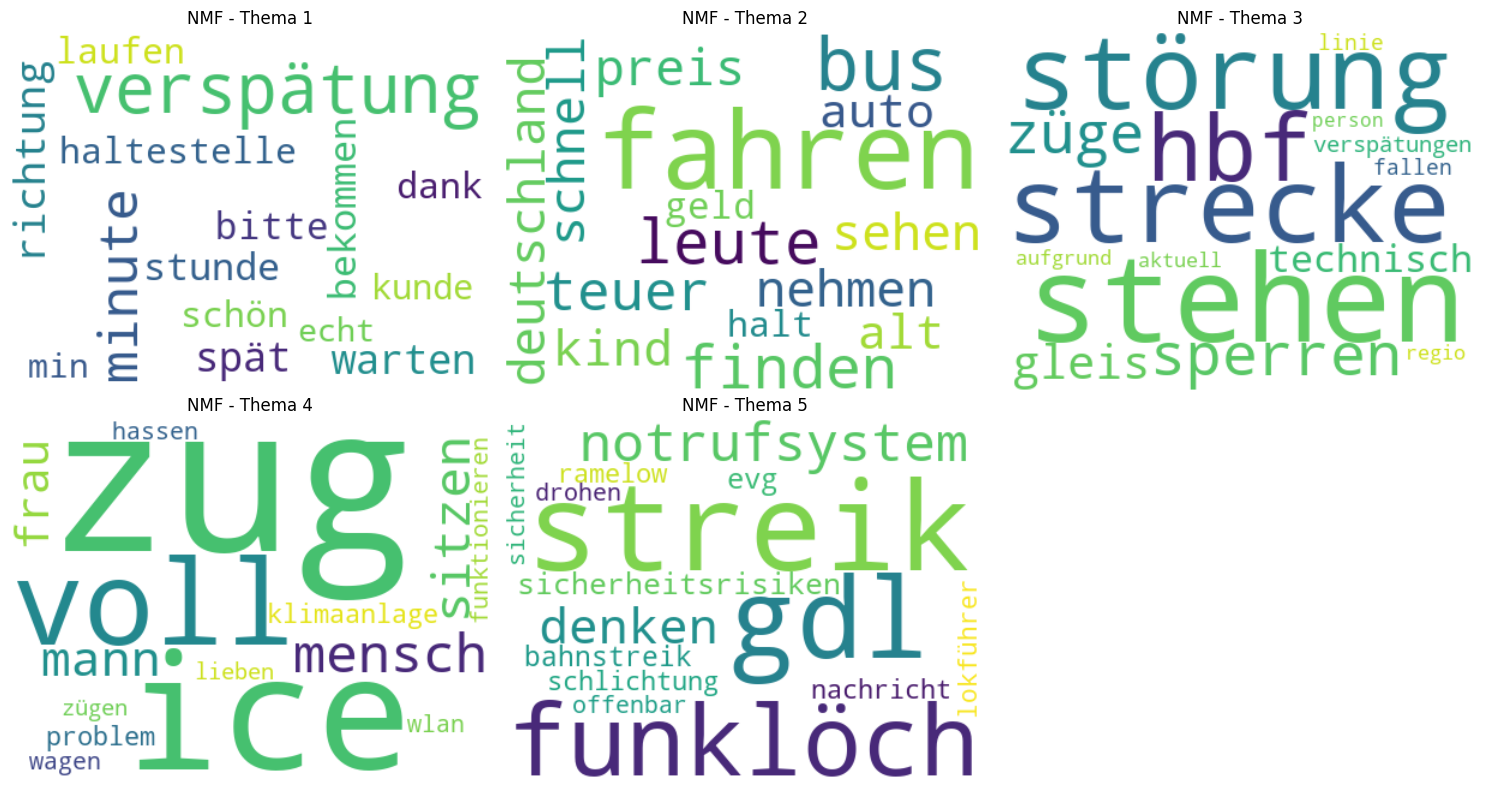

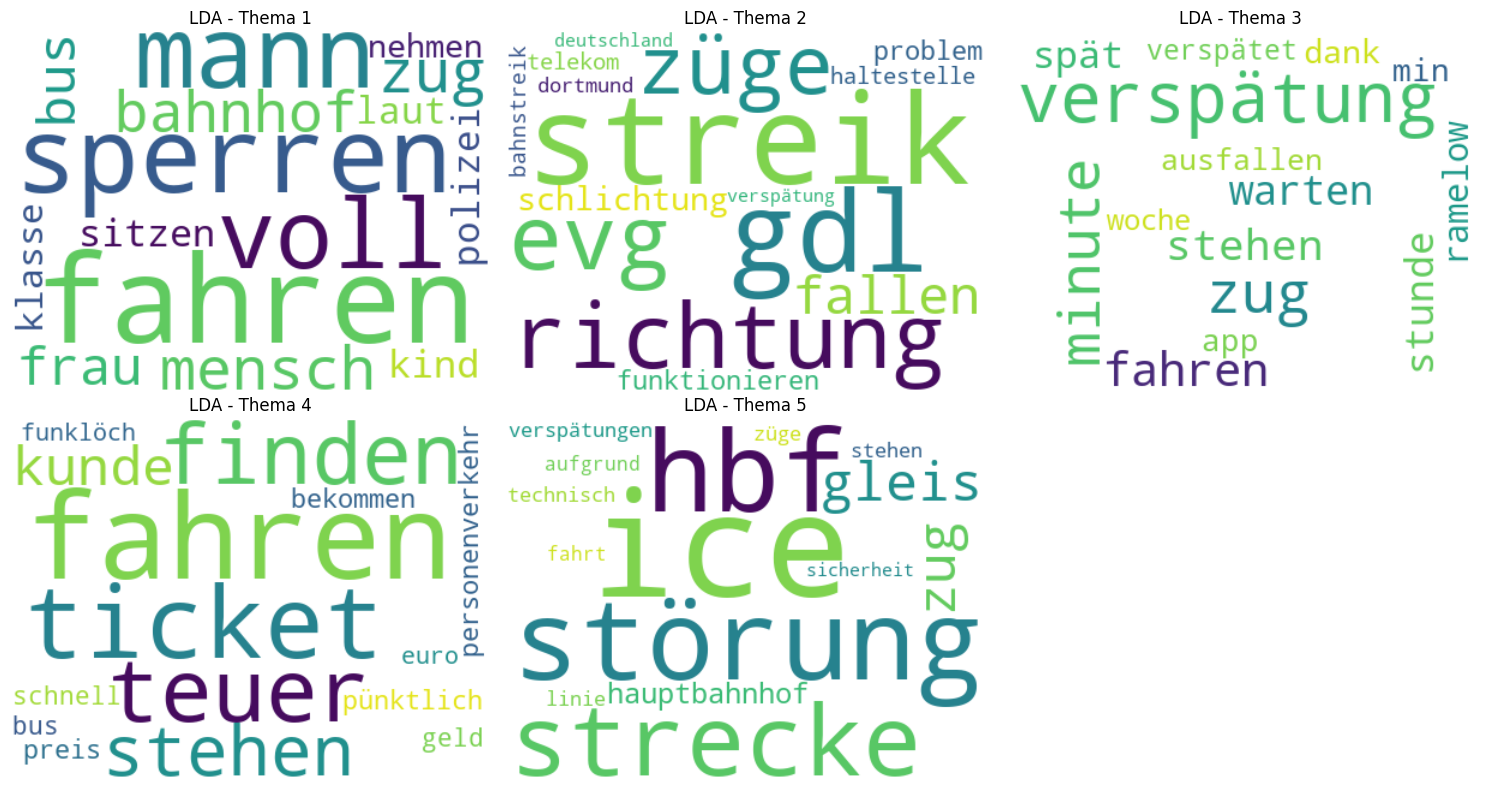

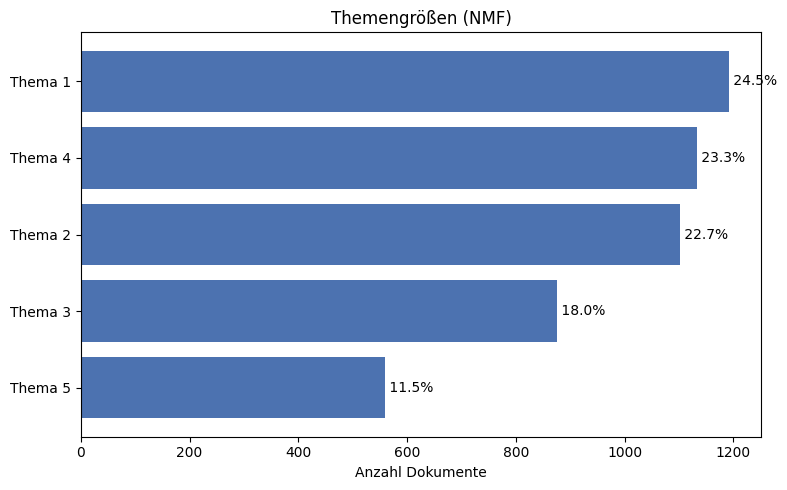

Themengrößen (NMF):
  Thema 1: 1192 Dokumente (24.5%)
  Thema 4: 1134 Dokumente (23.3%)
  Thema 2: 1102 Dokumente (22.7%)
  Thema 3: 876 Dokumente (18.0%)
  Thema 5: 559 Dokumente (11.5%)


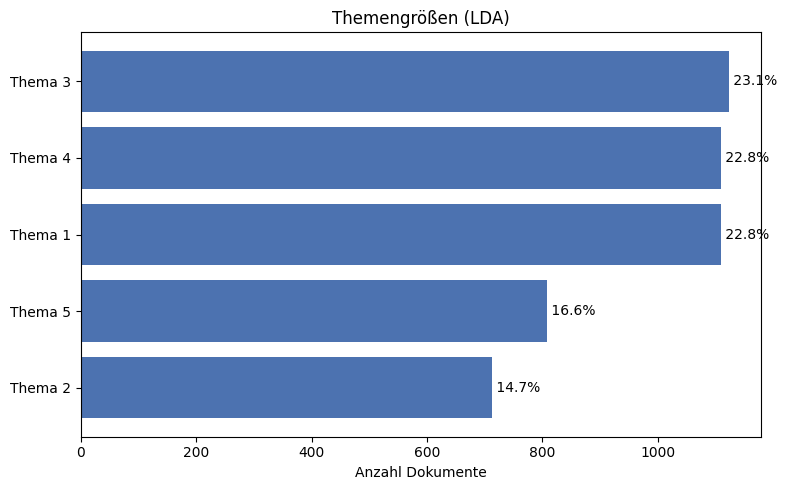

Themengrößen (LDA):
  Thema 3: 1123 Dokumente (23.1%)
  Thema 4: 1110 Dokumente (22.8%)
  Thema 1: 1110 Dokumente (22.8%)
  Thema 5: 807 Dokumente (16.6%)
  Thema 2: 713 Dokumente (14.7%)


In [10]:
# Eine Wortwolke je Thema, Schriftgröße entspricht dem Gewicht im Thema
def show_wordclouds(model, vectorizer, method, n_words=15):
    words = vectorizer.get_feature_names_out()
    n_topics = len(model.components_)
    cols = 3
    rows = (n_topics + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
    axes = axes.ravel()
    for i, topic in enumerate(model.components_):
        top_indices = topic.argsort()[::-1][:n_words]
        weights = {}
        for idx in top_indices:
            weights[words[idx]] = topic[idx]

        cloud = WordCloud(width=400, height=300, background_color="white",
                          colormap="viridis", random_state=24).generate_from_frequencies(weights)
        axes[i].imshow(cloud, interpolation="bilinear")
        axes[i].set_title(f"{method} - Thema {i + 1}")
        axes[i].axis("off")
    for j in range(n_topics, len(axes)):
        axes[j].axis("off")
    plt.tight_layout()
    plt.show()


# Ordnet jede Beschwerde ihrem stärksten Thema zu und zeigt die Themengrößen als Balkendiagramm
def show_topic_sizes(model, matrix, method):
    doc_topic = model.transform(matrix)
    n_topics = len(model.components_)
    counts = np.zeros(n_topics, dtype=int)
    for row in doc_topic:
        best = row.argmax()
        counts[best] = counts[best] + 1
    total = counts.sum()
    order = counts.argsort()[::-1]
    labels = []
    sizes = []
    for i in order:
        labels.append(f"Thema {i + 1}")
        sizes.append(counts[i])
    plt.figure(figsize=(8, 5))
    positions = range(len(labels))
    plt.barh(positions, sizes, color="#4C72B0")
    plt.yticks(positions, labels)
    plt.gca().invert_yaxis()
    plt.xlabel("Anzahl Dokumente")
    plt.title(f"Themengrößen ({method})")
    for i in positions:
        pct = 100 * sizes[i] / total
        plt.text(sizes[i], i, f" {pct:.1f}%", va="center")
    plt.tight_layout()
    plt.show()
    print(f"Themengrößen ({method}):")
    for i in order:
        pct = 100 * counts[i] / total
        print(f"  Thema {i + 1}: {counts[i]} Dokumente ({pct:.1f}%)")


show_wordclouds(nmf_model, tfidf_vectorizer, "NMF")
show_wordclouds(lda_model, bow_vectorizer, "LDA")
show_topic_sizes(nmf_model, tfidf_matrix, "NMF")
show_topic_sizes(lda_model, bow_matrix, "LDA")

## 7. Diskussion & Fazit

### Datenbasis

Von den 19.432 Texten des Rohdatensatzes bleiben nach dem Entfernen von 881 Duplikaten 18.551 übrig, und davon sind rund 4.900 als relevant und negativ markiert. Nur diese gehen in die Analyse ein. Der Filter kostet natürlich Datenmenge, ohne ihn funktioniert die Analyse jedoch nicht. In einem früheren Durchlauf ohne Filter landeten über 60 % aller Texte in einem einzigen Sammelthema, aus dem sich nichts ablesen ließ. Neutrale Nachrichten und Lob übertönen die Beschwerden.

### Häufigste Beschwerde-Themen (NMF, nach Größe)

| Thema | Anteil | Kernwörter |
|-------|--------|-----------|
| Verspätung und Wartezeit | ~24 % | verspätung, minute, spät, warten, stunde |
| Zustand der Züge und Mitreisende | ~23 % | zug, ice, voll, sitzen, klimaanlage, wagen |
| Preise und Bus | ~23 % | fahren, bus, teuer, preis, leute |
| Störungen und Strecke | ~18 % | strecke, störung, gleis, technisch, sperren |
| Streik und Sicherheit | ~12 % | streik, gdl, notrufsystem, sicherheitsrisiken, evg |

Verspätung ist damit das häufigste Thema und macht knapp ein Viertel aller Beschwerden aus. Streik und Sicherheit ist mit rund 12 % das kleinste der fünf. Diese Rangfolge ist die Information, die eine Verwaltung für die Priorisierung ihrer Maßnahmen benötigt.

Bei Thema 5 ist die Zahl allerdings mit Vorsicht zu lesen. Rund ein Fünftel der 559 Dokumente enthält das Wort `funklöcher` und besteht aus geteilten Nachrichtenmeldungen über Lücken im Notrufsystem der Bahn. Das sind keine selbst erlebten Beschwerden. Das Thema misst an dieser Stelle also eher Medienresonanz als Betroffenheit.

### NMF und LDA im Vergleich

Im Kern finden beide Verfahren dieselben Themen, nämlich Verspätung, Streik, Preise und Tickets, Störungen und volle Züge. Auch die Coherence-Werte liegen eng beieinander, 0,444 für NMF gegenüber 0,434 für LDA. Beide sind auf derselben Tokenbasis gerechnet.

Die Trennschärfe ist aufschlussreicher als der Zahlenwert. LDA vermischt stärker. In dessen Thema 1 fallen Streckensperrungen, volle Züge samt Mitreisenden und der Bus zusammen, also drei verschiedene Anliegen. NMF hält das in Thema 3 und Thema 4 auseinander. Für die Ableitung konkreter Maßnahmen ist die NMF-Aufteilung deshalb brauchbarer. Ein grundsätzlich überlegenes Verfahren lässt sich daraus jedoch nicht ableiten, dafür ist der Abstand zu gering.

Fairerweise gehört dazu, dass NMF hier auf TF-IDF läuft und LDA auf Bag-of-Words. Das ist die übliche Paarung, weil LDA Zähldaten voraussetzt. Der beobachtete Unterschied geht damit auf Modell und Vektorisierung zusammen zurück, sauber trennen lässt er sich in diesem Aufbau nicht.

### BoW und TF-IDF

Auf Wortebene unterscheiden sich die beiden Vektorisierungen kaum. Von den 15 häufigsten BoW-Wörtern und den 15 am stärksten gewichteten TF-IDF-Wörtern sind 14 dieselben, nur die Reihenfolge weicht ab. Verantwortlich dafür ist allein `min_df=10`, das alle Wörter aus weniger als zehn Beschwerden entfernt. Die zweite Schwelle `max_df=0.5` greift in diesem Korpus dagegen überhaupt nicht, denn kein einziges Wort steht in mehr als der Hälfte der Beschwerden. Das häufigste ist `fahren` mit 11,3 % Dokumentfrequenz. Der Wert liegt damit weit unter der Schwelle von 50 %.

Ein niedrigerer Wert wäre kein Ausweg. Damit `max_df` überhaupt greift, müsste die Schwelle unter 11 % liegen, und dort steht sie nur zwei Prozentpunkte über `zug` mit 9,3 % und `verspätung` mit 8,6 %. Eine Häufigkeitsschwelle kann inhaltsleere Verben wie `fahren` nicht von zentralen Substantiven trennen, weil beide ähnlich häufig sind. Das passende Mittel wäre ein Filter auf Wortarten.

Im Modell wirkt sich der Unterschied zwischen den Vektorisierungen trotzdem aus, weil TF-IDF häufige Wörter herunterdrückt und die NMF-Themen dadurch etwas schärfer werden.

Eine Schwäche liegt in den Grundformen. `zug`, `züge` und `zügen` sind drei getrennte Merkmale, ebenso `verspätung` und `verspätungen`. Sie landen teilweise sogar in verschiedenen Themen. Die Ursache ist nicht das Sprachmodell, sondern die Reihenfolge. spaCy bekommt die Texte erst, nachdem sie kleingeschrieben wurden. Ohne Großschreibung wird aus `Züge` dann kein `Zug` mehr. Kleinschreibung erst nach der Lemmatisierung behebt das.